## Starting with exploring the data of the Project

In [2]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path("..") / "data" / "raw"   # the notebook runs from notebooks/, so go up one level

# File sizes in MB, to confirm everything is there
for f in sorted(RAW_DIR.glob("*.csv")):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:8.1f} MB")

building_metadata.csv             0.0 MB
sample_submission.csv           447.6 MB
test.csv                       1462.5 MB
train.csv                       678.6 MB
weather_test.csv                 14.8 MB
weather_train.csv                 7.5 MB


In [3]:
# Building metadata
meta = pd.read_csv(RAW_DIR / "building_metadata.csv")

print(meta.shape)
meta.head()

(1449, 6)


,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,2008.0,NaN
1,0,1,Education,2720,2004.0,NaN
2,0,2,Education,5376,1991.0,NaN
3,0,3,Education,23685,2002.0,NaN
4,0,4,Education,116607,1975.0,NaN


In [4]:
# Building Weather
weather = pd.read_csv(RAW_DIR / "weather_train.csv", parse_dates=["timestamp"])

print(weather.shape)
weather.head()

(139773, 9)


,site_id,timestamp,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,2016-01-01 00:00:00,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
1,0,2016-01-01 01:00:00,24.4,NaN,21.1,-1.0,1020.2,70.0,1.5
2,0,2016-01-01 02:00:00,22.8,2.0,21.1,0.0,1020.2,0.0,0.0
3,0,2016-01-01 03:00:00,21.1,2.0,20.6,0.0,1020.1,0.0,0.0
4,0,2016-01-01 04:00:00,20.0,2.0,20.0,-1.0,1020.0,250.0,2.6


In [5]:
# Find type for each column, non-null count
meta.info(memory_usage="deep")
print()
weather.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   site_id      1449 non-null   int64  
 1   building_id  1449 non-null   int64  
 2   primary_use  1449 non-null   str    
 3   square_feet  1449 non-null   int64  
 4   year_built   675 non-null    float64
 5   floor_count  355 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 144.2 KB

<class 'pandas.DataFrame'>
RangeIndex: 139773 entries, 0 to 139772
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   site_id             139773 non-null  int64         
 1   timestamp           139773 non-null  datetime64[us]
 2   air_temperature     139718 non-null  float64       
 3   cloud_coverage      70600 non-null   float64       
 4   dew_temperature     139660 non-null  float64       
 5   preci

In [6]:
print("Metadata, % missing:")
print((meta.isna().mean() * 100).round(1))
print("\nWeather, % missing:")
print((weather.isna().mean() * 100).round(1))

Metadata, % missing:
site_id         0.0
building_id     0.0
primary_use     0.0
square_feet     0.0
year_built     53.4
floor_count    75.5
dtype: float64

Weather, % missing:
site_id                0.0
timestamp              0.0
air_temperature        0.0
cloud_coverage        49.5
dew_temperature        0.1
precip_depth_1_hr     36.0
sea_level_pressure     7.6
wind_direction         4.5
wind_speed             0.2
dtype: float64


### Understanding Meta and Weather

- `Meta: ` 1,449 buildings, 6 columns
    1. site_id, building_id, primary_use, square_feet : No null values
    2. year_built : 774 values missing out of 1449 (53%)
    3. floor_count : 1094 values missing out of 1449 (75%)

- `Weather: `  139,773 rows, 9 columns
    1. site_id, timestamp : No null values
    2. air_tempreture : 55 missing values (0.04%)
    3. cloud_coverage : 69,173 missing values (49.5%)
    4. dew_temperature : 113 missing values (0.1%)
    5. precip_depth_1_hr : 50,289 missing values (36.0%)
    6. sea_level_pressure :	10,618 missing values (7.6%)
    7. wind_direction : 6,268 missing values (4.5%)
    8. wind_speed : 304 missing values 	(0.2%)

In [7]:
# Check for duplicates

print("Duplicate metadata rows:", meta.duplicated().sum())
print("building_id unique:", meta["building_id"].is_unique)
print("Duplicate (site_id, timestamp) in weather:",
      weather.duplicated(subset=["site_id", "timestamp"]).sum())

Duplicate metadata rows: 0
building_id unique: True
Duplicate (site_id, timestamp) in weather: 0


In [8]:
# Check Meta (Number of sites, Buildings per site, Primary use for the building)
print("Number of sites:", meta["site_id"].nunique())    
print("Buildings per site:")
print(meta["site_id"].value_counts().sort_index())
print("Primary use: ", meta["primary_use"].value_counts())

Number of sites: 16
Buildings per site:
site_id
0     105
1      51
2     135
3     274
4      91
5      89
6      44
7      15
8      70
9     124
10     30
11      5
12     36
13    154
14    102
15    124
Name: count, dtype: int64
Primary use:  primary_use
Education                        549
Office                           279
Entertainment/public assembly    184
Public services                  156
Lodging/residential              147
Other                             25
Healthcare                        23
Parking                           22
Warehouse/storage                 13
Manufacturing/industrial          12
Retail                            11
Services                          10
Technology/science                 6
Food sales and service             5
Utility                            4
Religious worship                  3
Name: count, dtype: int64


In [9]:
meta[["square_feet", "year_built", "floor_count"]].describe().round(1)

,square_feet,year_built,floor_count
count,1449.0,675.0,355.0
mean,92111.8,1968.0,3.7
std,110770.0,31.1,3.3
min,283.0,1900.0,1.0
25%,23012.0,1949.0,1.0
50%,57673.0,1970.0,3.0
75%,115676.0,1995.0,5.0
max,875000.0,2017.0,26.0


In [ ]:
# Print the earliest and latest weather timestamp across all sites
print("Weather from", weather["timestamp"].min(), "to", weather["timestamp"].max())

# Build every hour between the first and last timestamp, then count them
expected_hours = len(pd.date_range(weather["timestamp"].min(),   # start: earliest timestamp
                                   weather["timestamp"].max(),   # end: latest timestamp
                                   freq="h"))                    # one step per hour
print("Expected hourly rows per site:", expected_hours)          # a complete site should have this many rows

# One summary row per site
per_site = weather.groupby("site_id").agg(   # split the table into one group per site
    rows=("timestamp", "size"),              # number of rows in that site
    first=("timestamp", "min"),              # that site's earliest timestamp
    last=("timestamp", "max"),               # that site's latest timestamp
)                                            # result: a table indexed by site_id

# Share of the expected hours that each site actually has, in %
per_site["pct_present"] = (per_site["rows"] / expected_hours * 100).round(1)  # e.g. 8784/8784 -> 100.0

# Sort so rows are in time order within each site (diff compares each row to the one above)
weather = weather.sort_values(["site_id", "timestamp"])

# Time since the previous row of the SAME site (first row of each site gives NaT)
gap = weather.groupby("site_id")["timestamp"].diff()

# Biggest gap per site; 1 hour means no missing hours
per_site["max_gap"] = gap.groupby(weather["site_id"]).max()  # group the gaps by site, keep the largest

per_site

Weather from 2016-01-01 00:00:00 to 2016-12-31 23:00:00
Expected hourly rows per site: 8784


,rows,first,last,pct_present,max_gap
site_id,,,,,
0,8784,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00
1,8763,2016-01-01 00:00:00,2016-12-31 23:00:00,99.8,0 days 06:00:00
2,8783,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
3,8780,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
4,8783,2016-01-01 01:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00
5,8755,2016-01-01 01:00:00,2016-12-31 23:00:00,99.7,0 days 09:00:00
6,8782,2016-01-01 01:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
7,8614,2016-01-01 00:00:00,2016-12-31 23:00:00,98.1,1 days 16:00:00
8,8784,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00


In [11]:
# Check train
peek = pd.read_csv(RAW_DIR / "train.csv", nrows=5000)  

print(peek.dtypes)                                     
print()
print(peek.describe())                                  
peek.head()                                             

building_id        int64
meter              int64
timestamp            str
meter_reading    float64
dtype: object

       building_id       meter  meter_reading
count  5000.000000  5000.00000   5.000000e+03
mean    760.867200     0.65700   1.699505e+03
std     446.662264     0.94442   6.488458e+04
min       0.000000     0.00000   0.000000e+00
25%     273.000000     0.00000   3.186550e+00
50%     852.500000     0.00000   3.669000e+01
75%    1169.000000     1.00000   1.519400e+02
max    1448.000000     3.00000   3.241630e+06


,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01 00:00:00,0.0
1,1,0,2016-01-01 00:00:00,0.0
2,2,0,2016-01-01 00:00:00,0.0
3,3,0,2016-01-01 00:00:00,0.0
4,4,0,2016-01-01 00:00:00,0.0


In [12]:
# Change datatypes for the columns to more compact types to save memory
train_dtypes = {
    "building_id": "int16",    
    "meter": "int8",          
    "meter_reading": "float32" 
}

# Load the full file, with new types
train = pd.read_csv(
    RAW_DIR / "train.csv",     
    dtype=train_dtypes,       
    parse_dates=["timestamp"], 
)

print(train.shape)                                                    
print(f"Memory: {train.memory_usage(deep=True).sum() / 1e6:.0f} MB")  
train.info()                                                           

(20216100, 4)
Memory: 303 MB
<class 'pandas.DataFrame'>
RangeIndex: 20216100 entries, 0 to 20216099
Data columns (total 4 columns):
 #   Column         Dtype         
---  ------         -----         
 0   building_id    int16         
 1   meter          int8          
 2   timestamp      datetime64[us]
 3   meter_reading  float32       
dtypes: datetime64[us](1), float32(1), int16(1), int8(1)
memory usage: 289.2 MB


In [13]:
# Check Missing values, Duplicates and Time range
print("Missing values per column:")
print(train.isna().sum())                                    

# Check duplicate rows that have the same variables in the columns (building_id, meter, timestamp)
dups = train.duplicated(subset=["building_id", "meter", "timestamp"]).sum()  
print("\nDuplicate (building, meter, timestamp) rows:", dups)

# Check the timerange and how many buildings the train file has
print("\nTime range:", train["timestamp"].min(), "to", train["timestamp"].max())  
print("Distinct timestamps:", train["timestamp"].nunique())  
print("Buildings in train:", train["building_id"].nunique(), "of", len(meta))  


Missing values per column:
building_id      0
meter            0
timestamp        0
meter_reading    0
dtype: int64

Duplicate (building, meter, timestamp) rows: 0

Time range: 2016-01-01 00:00:00 to 2016-12-31 23:00:00
Distinct timestamps: 8784
Buildings in train: 1449 of 1449


In [14]:
# Meter Codes : 
# 0 = Electricity
# 1 = Chilled Water
# 2 = Steam
# 3 = Hot Water

meter_summary = train.groupby("meter").agg(            
    rows=("meter_reading", "size"),                     
    buildings=("building_id", "nunique"),                
    median_reading=("meter_reading", "median"),          
    pct_zero=("meter_reading", lambda s: (s == 0).mean() * 100),  
)
meter_summary["pct_of_buildings"] = (meter_summary["buildings"] / len(meta) * 100).round(1)  
meter_summary.round(2)

,rows,buildings,median_reading,pct_zero,pct_of_buildings
meter,,,,,
0,12060910,1413,62.830002,4.40,97.5
1,4182440,498,120.489998,15.70,34.4
2,2708713,324,257.809998,12.81,22.4
3,1264037,145,39.619999,26.93,10.0


In [15]:
electricity = train[train["meter"]==0].drop(columns="meter")

electricity = electricity.merge(meta[["building_id", "site_id"]],
                                on="building_id",
                                how="left")

#del train

print(electricity.shape)
print("Rows without no side id : ", electricity["site_id"].isna().sum())
electricity.head()

(12060910, 4)
Rows without no side id :  0


,building_id,timestamp,meter_reading,site_id
0,0,2016-01-01,0.0,0
1,1,2016-01-01,0.0,0
2,2,2016-01-01,0.0,0
3,3,2016-01-01,0.0,0
4,4,2016-01-01,0.0,0


In [16]:
# Sumary of electricity meter reading

r = electricity["meter_reading"]

print(r.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).round(1))

print("Zeros: ", (r==0).sum(), "| %:", round((r==0).mean() * 100, 2))
print("Negative results: ", (r < 0).sum(), "| %:", round((r<0).mean() * 100, 2))

print("Top 10 buildings consuming electricity are :")
print(electricity.groupby("building_id")["meter_reading"].max().sort_values(ascending=False).head(10).round(0))


count    12060910.0
mean          170.8
std           380.8
min             0.0
1%              0.0
25%            19.5
50%            62.8
75%           170.1
99%          1629.6
99.9%        4988.0
max         79769.0
Name: meter_reading, dtype: float64
Zeros:  530169 | %: 4.4
Negative results:  0 | %: 0.0
Top 10 buildings consuming electricity are :
building_id
993     79769.0
1168    44336.0
954     41552.0
904     30268.0
799     17502.0
927     12571.0
881     11624.0
955     11019.0
921     10725.0
983     10295.0
Name: meter_reading, dtype: float32


### Analyzing key findings

- The `mean` (170.8) is 2.7x the `median` (62.8). The distribution is strongly right-skewed: a small share of very large readings pulls the mean up.

- The `max` (79,769) is 16x the `99.9th percentile` (4,988). About 12,000 readings (0.1%) lie above 4,988, and a few far beyond it. These could be very large buildings or errors, to check per building and site.

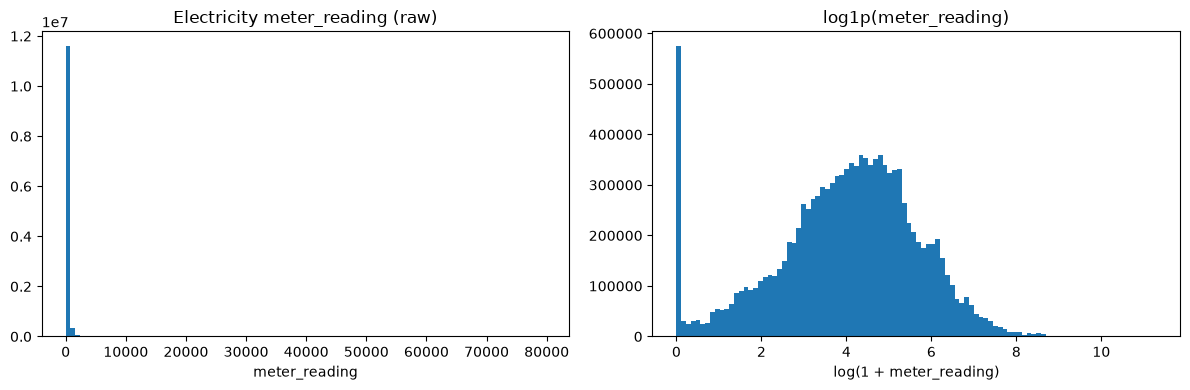

In [17]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))           # two plots side by side

axes[0].hist(r, bins=100)                                  # raw values
axes[0].set_title("Electricity meter_reading (raw)")
axes[0].set_xlabel("meter_reading")

axes[1].hist(np.log1p(r), bins=100)                        # log(1 + x) of the values
axes[1].set_title("log1p(meter_reading)")
axes[1].set_xlabel("log(1 + meter_reading)")

plt.tight_layout()                                         # stop labels from overlapping
plt.show()

# Analyzing the Histograms

- `Raw` data is extremely right skewed, on `log1p` scale it is more of bell shape (still has a spike at 0, from the 4.4% of 0 electricity meter readings )

- Log1p scale will be used for the modeling

In [84]:
electricity.head()

meter_summary = train.groupby("meter").agg(            
    rows=("meter_reading", "size"),                     
    buildings=("building_id", "nunique"),                
    median_reading=("meter_reading", "median"),          
    pct_zero=("meter_reading", lambda s: (s == 0).mean() * 100),  
)
meter_summary["pct_of_buildings"] = (meter_summary["buildings"] / len(meta) * 100).round(1)  
meter_summary.round(2)

,rows,buildings,median_reading,pct_zero,pct_of_buildings
meter,,,,,
0,12060910,1413,62.830002,4.40,97.5
1,4182440,498,120.489998,15.70,34.4
2,2708713,324,257.809998,12.81,22.4
3,1264037,145,39.619999,26.93,10.0


In [85]:
site_summary = electricity.groupby("site_id").agg(
    rows=("meter_reading", "size"),                     
    buildings=("building_id", "nunique"),                
    median_reading=("meter_reading", "median"),          
    pct_zero=("meter_reading", lambda s: (s == 0).mean() * 100),  
)
site_summary["pct_present"] = (
    site_summary["rows"] / (site_summary["buildings"] * expected_hours) * 100
).round(1)
site_summary.round(2)

,rows,buildings,median_reading,pct_zero,pct_present
site_id,,,,,
0,908409,105,70.440002,38.139999,98.5
1,447982,51,87.870003,0.000000,100.0
2,1184512,135,86.160004,0.840000,99.9
3,2370097,274,46.660000,0.130000,98.5
4,746746,91,70.480003,0.520000,93.4
5,781776,89,10.740000,1.030000,100.0
6,315436,36,84.870003,0.010000,99.8
7,104784,12,1163.260010,12.060000,99.4
8,567915,70,13.330000,4.680000,92.4


In [49]:
candidate_sites = [2, 3, 13]

# What the site_summary table says we should have
expected = site_summary.loc[candidate_sites]
expected_rows = expected["rows"].sum()
expected_buildings = expected["buildings"].sum()

print(expected_rows)
print(expected_buildings)


4791269
550


### Choosing candidate sites

- Site Id : 2, 3, 13
- Rows : 4,791,269
- Buildings : 550

In [47]:
# We create a table containing only the three candidate sites
# We sort this table to show every building by sorting the building_id and the timestamp

candidates = electricity[electricity["site_id"].isin([2, 3, 13])].sort_values(["building_id", "timestamp"]).reset_index(drop=True)

candidates.head()

,building_id,timestamp,meter_reading,site_id
0,156,2016-01-01 00:00:00,114.709999,2
1,156,2016-01-01 01:00:00,117.870003,2
2,156,2016-01-01 02:00:00,122.699997,2
3,156,2016-01-01 03:00:00,118.419998,2
4,156,2016-01-01 04:00:00,130.339996,2


In [50]:
len(candidates)

4791269

In [52]:
candidates["building_id"].nunique()

550

In [ ]:
# New column, showing the time difference since the last measurement
candidates["time_gap"] = candidates.groupby("building_id")["timestamp"].diff()

candidates.head()

,building_id,timestamp,meter_reading,site_id,time_gap
0,156,2016-01-01 00:00:00,114.709999,2,NaT
1,156,2016-01-01 01:00:00,117.870003,2,0 days 01:00:00
2,156,2016-01-01 02:00:00,122.699997,2,0 days 01:00:00
3,156,2016-01-01 03:00:00,118.419998,2,0 days 01:00:00
4,156,2016-01-01 04:00:00,130.339996,2,0 days 01:00:00


In [57]:
candidates["time_gap"].isna().sum()

np.int64(550)

In [63]:
per_building = candidates.groupby("building_id").agg(
    site_id = ("site_id", "first"),
    rows = ("timestamp", "size"),
    first_ts = ("timestamp", "min"),
    last_ts = ("timestamp", "max"),
    max_gap = ("time_gap", "max")
)

per_building["missing_hours"] = expected_hours - per_building["rows"]

per_building.head()

,site_id,rows,first_ts,last_ts,max_gap,missing_hours
building_id,,,,,,
156,2,8783,2016-01-01,2016-12-31 23:00:00,0 days 02:00:00,1
157,2,8783,2016-01-01,2016-12-31 23:00:00,0 days 02:00:00,1
158,2,8783,2016-01-01,2016-12-31 23:00:00,0 days 02:00:00,1
159,2,8773,2016-01-01,2016-12-31 23:00:00,0 days 03:00:00,11
160,2,8610,2016-01-01,2016-12-31 23:00:00,0 days 08:00:00,174


In [64]:
len(per_building)

550

In [65]:
per_building["rows"].sum()

np.int64(4791269)

In [70]:
# Finding the most common time gaps in building measuremetns
per_building["max_gap"].value_counts().head(20)

max_gap
0 days 02:00:00     312
1 days 01:00:00      88
0 days 01:00:00      84
0 days 03:00:00      12
0 days 08:00:00       9
0 days 06:00:00       7
0 days 04:00:00       4
0 days 05:00:00       3
5 days 01:00:00       3
3 days 01:00:00       3
0 days 07:00:00       2
7 days 01:00:00       2
0 days 17:00:00       2
6 days 04:00:00       2
0 days 16:00:00       1
0 days 21:00:00       1
9 days 01:00:00       1
1 days 00:00:00       1
46 days 01:00:00      1
31 days 01:00:00      1
Name: count, dtype: int64

In [82]:
# Finding how many buildings have a 1 day gap in measurements, grouping by site
per_building[per_building["max_gap"] > pd.Timedelta(hours=24)].groupby("site_id").size()

site_id
3     103
13      6
dtype: int64

In [72]:
per_building.groupby("site_id")["missing_hours"].describe()

,count,mean,std,min,25%,50%,75%,max
site_id,,,,,,,,
2,135.0,9.837037,38.368638,0.0,1.0,2.0,3.0,381.0
3,274.0,134.010949,744.574272,0.0,2.0,2.0,26.0,8305.0
13,141.0,13.361702,47.948525,0.0,0.0,0.0,2.0,298.0


In [94]:
# Rows where the gap since the previous reading is exactly 1 day 1 hour (24 missing hours)
one_day_gap = candidates[candidates["time_gap"] == pd.Timedelta(days=1, hours=1)]

print("Rows with a 25-hour gap:", len(one_day_gap))

# Which site + timestamp do these gaps end at? (timestamp = first reading AFTER the gap)
one_day_gap[["site_id", "timestamp"]].value_counts().head(25)

Rows with a 25-hour gap: 105


site_id  timestamp          
3        2016-05-25 00:00:00    50
         2016-07-30 00:00:00    25
         2016-02-10 01:00:00     6
         2016-03-05 01:00:00     6
         2016-07-18 00:00:00     5
         2016-02-13 01:00:00     2
         2016-04-08 00:00:00     2
         2016-05-03 00:00:00     2
         2016-12-29 01:00:00     1
         2016-05-23 00:00:00     1
         2016-05-26 00:00:00     1
         2016-10-15 00:00:00     1
         2016-10-29 00:00:00     1
         2016-11-12 01:00:00     1
13       2016-04-24 10:00:00     1
Name: count, dtype: int64

In [90]:
per_building.nlargest(10, "missing_hours")

,site_id,rows,first_ts,last_ts,max_gap,missing_hours
building_id,,,,,,
403,3,479,2016-12-12 01:00:00,2016-12-31 23:00:00,0 days 01:00:00,8305
420,3,2327,2016-01-01 00:00:00,2016-04-06 23:00:00,0 days 02:00:00,6457
555,3,4657,2016-06-20 06:00:00,2016-12-31 23:00:00,0 days 17:00:00,4127
528,3,5231,2016-05-28 00:00:00,2016-12-31 23:00:00,0 days 02:00:00,3553
487,3,6095,2016-01-01 00:00:00,2016-09-11 23:00:00,1 days 01:00:00,2689
341,3,6935,2016-01-01 00:00:00,2016-10-16 23:00:00,1 days 01:00:00,1849
376,3,7486,2016-01-01 00:00:00,2016-12-31 23:00:00,46 days 01:00:00,1298
469,3,7499,2016-01-01 00:00:00,2016-12-31 23:00:00,52 days 12:00:00,1285
299,3,7965,2016-02-04 01:00:00,2016-12-31 23:00:00,0 days 02:00:00,819


### Missing hours, candidate sites

| Site | Buildings | Total missing h | Missing h per building | Median missing h | Max missing h | Buildings with gap > 24 h |
|---|---|---|---|---|---|---|
| 2  | 135 | 1,328  | ≈ 10  | 2 | 381   | 0   |
| 3  | 274 | 36,719 | ≈ 134 | 2 | 8,305 | 103 |
| 13 | 141 | 1,884  | ≈ 13  | 0 | 298   | 6   |

- **Site 3:** the typical building is fine (median 2 h), but a quarter of buildings miss ≥ 26 h. The 10 worst buildings are all on site 3:
    - **late start:** e.g. building 403 only starts on 12 Dec (479 readings in the year)
    - **early stop:** e.g. building 420 stops on 6 Apr
    - **holes in the middle:** 31 to 52 days (buildings 413, 376, 469)
- **Shared outages on site 3:** 50 buildings are missing all of 24 May 2016 and 25 buildings all of 29 July 2016, plus smaller groups on other dates. Only part of the site is affected each time.
- **Sites 2 and 13:** clean. Site 2 has no gap longer than a day; site 13 has 6 buildings with one.
- **Method note:** `max_gap` misses late starts and early stops, because `.diff()` only measures between readings that exist (building 403 has `max_gap` = 1 h but is missing 8,305 h). `missing_hours` is the more reliable measure.
- **Weather** is complete for all three candidates (1 to 4 missing hours, max gap 2 h), so it doesn't separate them.

**Conclusion:** site 3 is ruled out on missing data. Sites 2 and 13 go on to the zero-run check.

In [ ]:
#  Xreate new table containing only sites 2 and 13
finalists = electricity[electricity["site_id"].isin([2, 13])].sort_values(["building_id", "timestamp"]).reset_index(drop=True)

finalists.head()

,building_id,timestamp,meter_reading,site_id
0,156,2016-01-01 00:00:00,114.709999,2
1,156,2016-01-01 01:00:00,117.870003,2
2,156,2016-01-01 02:00:00,122.699997,2
3,156,2016-01-01 03:00:00,118.419998,2
4,156,2016-01-01 04:00:00,130.339996,2


In [ ]:
# New column, boolean value for when the meter reading is 0
finalists["is_zero"] = (finalists["meter_reading"] == 0)

In [96]:
len(finalists)

2421172

In [97]:
finalists["building_id"].nunique()

276

In [117]:
# How many zero vs non-zero readings overall
finalists["is_zero"].value_counts()

is_zero
False    2391354
True       29818
Name: count, dtype: int64

In [118]:
# Zero vs non-zero per site
finalists[["site_id", "is_zero"]].value_counts().sort_index()

site_id  is_zero
2        False      1174568
         True          9944
13       False      1216786
         True         19874
Name: count, dtype: int64

In [120]:
# Buildings with the most zero readings, with their site
finalists[finalists["is_zero"]][["site_id", "building_id"]].value_counts().head(10)

site_id  building_id
13       1221           7404
         1169           5176
         1113           5003
2        260            2560
         258            2282
         180            1962
         186             759
         177             513
         269             513
13       1153            472
Name: count, dtype: int64

In [126]:
# Previous hour's is_zero for the SAME building (first row of each building gets NaN)
prev_is_zero = finalists.groupby("building_id")["is_zero"].shift()

# A new run starts when is_zero differs from the previous hour (or it's a building's first row)
finalists["new_run"] = finalists["is_zero"] != prev_is_zero

# Running total of run starts -> every run gets its own number
finalists["run_id"] = finalists["new_run"].cumsum()

finalists.head(100)

,building_id,timestamp,meter_reading,site_id,is_zero,new_run,run_id
0,156,2016-01-01 00:00:00,114.709999,2,False,True,1
1,156,2016-01-01 01:00:00,117.870003,2,False,False,1
2,156,2016-01-01 02:00:00,122.699997,2,False,False,1
3,156,2016-01-01 03:00:00,118.419998,2,False,False,1
4,156,2016-01-01 04:00:00,130.339996,2,False,False,1
...,...,...,...,...,...,...,...
95,156,2016-01-04 23:00:00,135.919998,2,False,False,1
96,156,2016-01-05 00:00:00,136.089996,2,False,False,1
97,156,2016-01-05 01:00:00,136.240005,2,False,False,1
98,156,2016-01-05 02:00:00,136.850006,2,False,False,1


In [128]:
print("Total runs:", finalists["run_id"].max())
print("Max buildings per run:", finalists.groupby("run_id")["building_id"].nunique().max())

Total runs: 1866
Max buildings per run: 1


In [129]:
b = finalists[finalists["building_id"] == 260]
first_zero = b.index[b["is_zero"]][0]          # row index of its first zero reading
finalists.loc[first_zero - 3 : first_zero + 5]  # a few rows before and after

,building_id,timestamp,meter_reading,site_id,is_zero,new_run,run_id
915536,260,2016-05-10 19:00:00,188.820007,2,False,False,804
915537,260,2016-05-10 20:00:00,195.759995,2,False,False,804
915538,260,2016-05-10 21:00:00,54.160000,2,False,False,804
915539,260,2016-05-10 22:00:00,0.000000,2,True,True,805
915540,260,2016-05-10 23:00:00,0.000000,2,True,False,805
915541,260,2016-05-11 00:00:00,0.000000,2,True,False,805
915542,260,2016-05-11 01:00:00,0.000000,2,True,False,805
915543,260,2016-05-11 02:00:00,0.000000,2,True,False,805
915544,260,2016-05-11 03:00:00,0.000000,2,True,False,805


In [130]:
finalists[finalists["new_run"] & finalists["is_zero"]].head(10)

,building_id,timestamp,meter_reading,site_id,is_zero,new_run,run_id
76408,164,2016-09-21 07:00:00,0.0,2,True,True,10
77199,164,2016-10-24 06:00:00,0.0,2,True,True,12
79498,165,2016-01-29 11:00:00,0.0,2,True,True,15
80425,165,2016-03-08 02:00:00,0.0,2,True,True,17
80449,165,2016-03-09 02:00:00,0.0,2,True,True,19
81921,165,2016-05-09 22:00:00,0.0,2,True,True,21
82209,165,2016-05-21 22:00:00,0.0,2,True,True,23
82225,165,2016-05-22 14:00:00,0.0,2,True,True,25
82856,165,2016-06-18 02:00:00,0.0,2,True,True,27
84952,165,2016-09-13 21:00:00,0.0,2,True,True,29


In [131]:
# Keep only zero readings, then summarise each zero run
zero_runs = finalists[finalists["is_zero"]].groupby("run_id").agg(
    building_id=("building_id", "first"),
    site_id=("site_id", "first"),
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    length_h=("timestamp", "size"),   # number of zero readings in the run
)

print("Zero runs:", len(zero_runs))
print("Zero readings covered:", zero_runs["length_h"].sum())
zero_runs.sort_values("length_h", ascending=False).head(10)


Zero runs: 798
Zero readings covered: 29818


,building_id,site_id,start,end,length_h
run_id,,,,,
1860,1221,13,2016-01-01 00:00:00,2016-11-04 11:00:00,7404
1729,1169,13,2016-01-01 00:00:00,2016-08-03 15:00:00,5176
1507,1113,13,2016-01-01 00:00:00,2016-07-27 10:00:00,5003
799,258,2,2016-09-25 14:00:00,2016-12-12 09:00:00,1868
70,180,2,2016-02-20 08:00:00,2016-04-05 11:00:00,1083
74,180,2,2016-09-22 19:00:00,2016-10-20 09:00:00,663
59,177,2,2016-06-03 23:00:00,2016-06-25 00:00:00,506
1285,269,2,2016-06-03 23:00:00,2016-06-25 00:00:00,506
1669,1153,13,2016-01-01 00:00:00,2016-01-20 14:00:00,471


In [132]:
# Longest zero run and number of zero runs, per building
zero_by_building = zero_runs.groupby("building_id").agg(
    site_id=("site_id", "first"),
    n_zero_runs=("length_h", "size"),
    longest_run_h=("length_h", "max"),
)

# How many buildings per site have a long zero run
summary = zero_by_building.groupby("site_id").agg(
    buildings_with_zeros=("longest_run_h", "size"),
    run_over_1_day=("longest_run_h", lambda s: (s > 24).sum()),
    run_over_1_week=("longest_run_h", lambda s: (s > 168).sum()),
    run_over_30_days=("longest_run_h", lambda s: (s > 720).sum()),
)
summary


,buildings_with_zeros,run_over_1_day,run_over_1_week,run_over_30_days
site_id,,,,
2,62,10,6,2
13,49,16,4,3


### Site 2 vs site 13: everything we know so far

| Check | Site 2 | Site 13 | Better |
|---|---|---|---|
| **Size** | | | |
| Buildings (electricity) | 135 | 141 | ≈ |
| Rows | 1,184,512 | 1,236,660 | ≈ |
| Median reading | 86.2 | 106.7 | n/a |
| **Missing data** | | | |
| % present | 99.9 | 99.8 | ≈ |
| Total missing hours | 1,328 | 1,884 | 2 |
| Missing hours per building | ≈ 10 | ≈ 13 | 2 |
| Median missing hours per building | 2 | 0 | 13 |
| Max missing hours (worst building) | 381 | 298 | 13 |
| Buildings with a gap > 24 h | **0** | 6 | **2** |
| **Weather** | | | |
| Weather hours present (of 8,784) | 8,783 | 8,783 | ≈ |
| Weather max gap | 2 h | 2 h | ≈ |
| **Zero readings** | | | |
| Zero readings | **9,944 (0.84%)** | 19,874 (1.61%) | **2** |
| Buildings with any zero | 62 | 49 | 13 |
| Buildings with a zero run > 1 day | **10** | 16 | **2** |
| Buildings with a zero run > 1 week | 6 | **4** | 13 |
| Buildings with a zero run > 30 days | **2** | 3 | **2** |
| Longest zero run | 1,868 h (building 258) | 7,404 h (building 1221) | 2 |
| **Where the long zero runs are** | Mid / late year: 180 (20 Feb–5 Apr, 22 Sep–20 Oct), 177 and 269 (3–25 Jun, same dates), 258 (25 Sep–12 Dec) | Start of year: 1221, 1169, 1113, 1153 are all zero from 1 Jan (meters probably not recording yet) | see note |

**Notes**
- Zeros are concentrated in a few buildings on both sites: the top buildings hold ≈ 86% (site 2) and ≈ 88% (site 13) of each site's zeros.
- Site 13's long zero runs are effectively **late starts**: they only affect the start of the year (training period).
- Site 2's long zero runs fall **mid and late year**, so some (e.g. building 258, zero until 12 Dec) would land in validation or test. Handle in Stage 3 by excluding buildings with a zero run > 1 week (6 buildings, leaving 129).

Not decided yet. The table above compares the sites before cleaning, which makes site 2 look better. That isn't a fair comparison: both sites have a few buildings that are mostly zeros and would be excluded anyway. Before deciding, we need to apply the same exclusion rule to both sites (drop buildings with a zero run > 1 week) and recompare buildings left, zeros left and long gaps left. That's the next cell.

In [ ]:
# Buildings with a zero run longer than 1 week (same rule for both sites)
bad = zero_by_building[zero_by_building["longest_run_h"] > 168].index

clean = finalists[~finalists["building_id"].isin(bad)]

# Buildings with a gap > 24 h, among the ones we keep
gap_bld = per_building[(per_building["max_gap"] > pd.Timedelta(hours=24))
                       & (~per_building.index.isin(bad))]

pd.DataFrame({
    "buildings_left": clean.groupby("site_id")["building_id"].nunique(),
    "zeros_left": clean.groupby("site_id")["is_zero"].sum(),
    "pct_zero_left": (clean.groupby("site_id")["is_zero"].mean() * 100).round(2),
    "gap_over_24h_left": gap_bld.groupby("site_id").size(),
}).fillna(0)

,buildings_left,zeros_left,pct_zero_left,gap_over_24h_left
site_id,,,,
2,129.0,4193.0,0.37,0.0
3,0.0,0.0,0.00,103.0
13,137.0,1819.0,0.15,6.0


In [ ]:
# Site 13 buildings (kept after cleaning) with a gap > 24 h
gap_bld[gap_bld["site_id"] == 13]

,site_id,rows,first_ts,last_ts,max_gap,missing_hours
building_id,,,,,,
1080,13,8738,2016-01-01,2016-12-31 23:00:00,1 days 23:00:00,46
1148,13,8663,2016-01-01,2016-12-31 23:00:00,5 days 02:00:00,121
1159,13,8637,2016-01-01,2016-12-31 23:00:00,6 days 04:00:00,147
1168,13,8528,2016-01-01,2016-12-31 23:00:00,6 days 04:00:00,256
1214,13,8753,2016-01-01,2016-12-31 23:00:00,1 days 08:00:00,31
1222,13,8489,2016-01-01,2016-12-31 23:00:00,8 days 05:00:00,295


### After cleaning: site 2 vs site 13

**Exclusion rule (same for both sites):** drop buildings whose longest zero run is longer than 1 week (> 168 h).
- Site 2: 6 buildings excluded (mid / late-year outages, e.g. 258, 180, 177, 269)
- Site 13: 4 buildings excluded (1221, 1169, 1113, 1153, all zero from 1 Jan, i.e. meters not recording yet)

| After cleaning | Site 2 | Site 13 | Better |
|---|---|---|---|
| Buildings left | 129 | **137** | **13** |
| Zero readings left | 4,193 | **1,819** | **13** |
| % zero left | 0.37% | **0.15%** | **13** |
| Buildings with a gap > 24 h left | **0** | 6 | 2 |

**Site 13's 6 remaining gap buildings are minor:**
- all cover the full year (1 Jan → 31 Dec), so these are short holes, not late starts or early stops
- longest gap 8 days 5 h (building 1222); missing hours per building 31 to 295 (at most ≈ 3% of the year)
- 1159 and 1168 have the same gap length (6 days 4 h), probably a shared outage
- they can be handled in Stage 3 as missing hours, so there's no need to exclude them

## Decision: site 13

**Reasons**
- After the same cleaning rule, site 13 keeps **more buildings** (137 vs 129) with **fewer zeros** (0.15% vs 0.37%).
- Its excluded buildings are **start-of-year late starts**, so they only touched the early (training) part of the year. Site 2's outages fall mid and late year, where they would affect validation and test.
- Its remaining gaps are short (≤ 8 days) and in otherwise complete buildings.
- Weather is complete (8,783 of 8,784 hours, max gap 2 h).

**Carried forward to Stage 3**
- Exclude buildings 1221, 1169, 1113, 1153.
- Treat the 6 short gaps (1080, 1148, 1159, 1168, 1214, 1222) and any remaining zeros as missing data.
- Still to check in Stage 1: spikes (building 1168 had the 2nd-highest reading in the whole dataset, 44,336) and the weather time zone.